# LAB Processing graphs with NetworkX

## The lab was fulfilled by Pozhylenkov Andrew (group K-10)

### Task <b>20</b>
<b>Teacher: Andrii Liashko</b>
<br>
build graph with <b>10</b> nodes, <b>12</b> edges, <b>4</b> connected components

In [1]:
import networkx as nx
import matplotlib.pyplot as plt

### 1 Graph construction

In [2]:
g = nx.Graph()
g.add_nodes_from(range(1,11))
g.add_edges_from([(1,2), (1,3), (1,4), (2,3), (2,4), (3,4),
                  (5,6), (5,7), (5,8), (6,7), (6,8), (7,8)])

The number of nodes:

In [3]:
print(f'Number of nodes: {g.number_of_nodes()}')

Number of nodes: 10


The number of edges:

In [4]:
print(f'Number of edges: {g.number_of_edges()}')

Number of edges: 12


The number of connected components:

In [5]:
print(f'Number of connected components: {nx.number_connected_components(g)}')

Number of connected components: 4


In [6]:
nx.write_adjlist(g, 'graph.txt')

### 2 Graph loading and visualization

In [7]:
g = nx.read_adjlist('graph.txt', nodetype=int)

In [8]:
g.nodes

NodeView((1, 2, 3, 4, 5, 6, 7, 8, 9, 10))

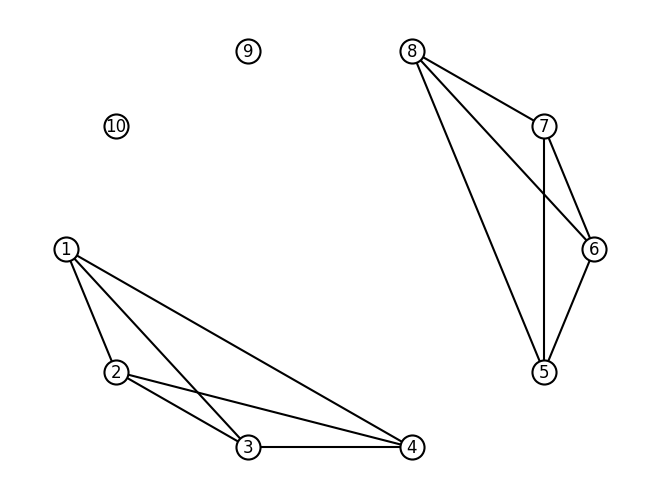

In [9]:
position = nx.shell_layout(g)
nx.draw(g, pos=position, with_labels=True, font_color='black',
        node_color='white', edge_color = 'black', edgecolors='black', linewidths=1.5, width=1.5)
plt.savefig('task2.jpg')
plt.show()

### 3 Nodes positioning

In [10]:
pos = {1:(0, 0),
       2:(1, 2),
       3:(2, 0),
       4:(1, 1),
       5:(5, 1),
       6:(5, 2),
       7:(4, 0),
       8:(6, 0),
       9:(7, 0),
       10:(8, 0)
       }

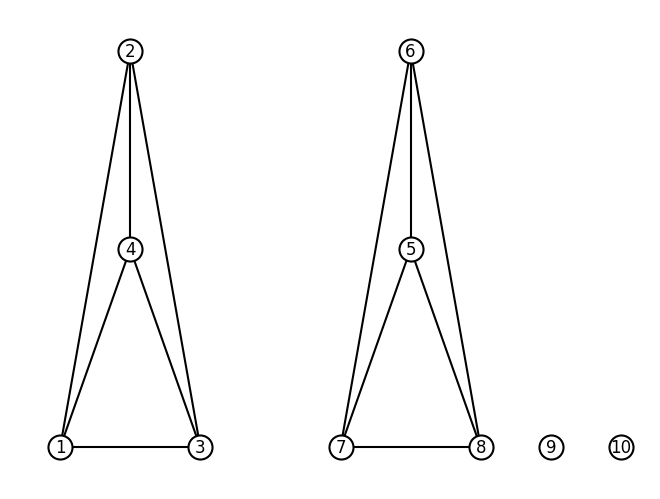

In [11]:
nx.draw(g, pos, with_labels=True, node_color='white', 
        edge_color = 'black', edgecolors='black', linewidths=1.5, width=1.5)
plt.savefig('task3.jpg')
plt.show()

### 4 Connected components

In [12]:
connected_components = nx.connected_components(g)
connected_component_index = iter(range(1, nx.number_connected_components(g) + 1))
node_index = iter(range(1, g.number_of_nodes() + 1))

for component in connected_components:
    subgraph = g.subgraph(component)
    connected_component_name = next(connected_component_index)

    print(f'Connected component {connected_component_name}'.center(50, '_'))
    print(f'Number of nodes: {subgraph.number_of_nodes()} | Number of edges: {subgraph.number_of_edges()}')
    print(f'Radius: {nx.radius(subgraph)} | Diametr: {nx.diameter(subgraph)}')
    
    for node in sorted(subgraph.nodes()):
        index = next(node_index)
        eccentricity = nx.eccentricity(subgraph, index)
        node_degree = subgraph.degree[index]

        print(f'Node {index}: degree: {node_degree}, eccentricity: {eccentricity}')

______________Connected component 1_______________
Number of nodes: 4 | Number of edges: 6
Radius: 1 | Diametr: 1
Node 1: degree: 3, eccentricity: 1
Node 2: degree: 3, eccentricity: 1
Node 3: degree: 3, eccentricity: 1
Node 4: degree: 3, eccentricity: 1
______________Connected component 2_______________
Number of nodes: 4 | Number of edges: 6
Radius: 1 | Diametr: 1
Node 5: degree: 3, eccentricity: 1
Node 6: degree: 3, eccentricity: 1
Node 7: degree: 3, eccentricity: 1
Node 8: degree: 3, eccentricity: 1
______________Connected component 3_______________
Number of nodes: 1 | Number of edges: 0
Radius: 0 | Diametr: 0
Node 9: degree: 0, eccentricity: 0
______________Connected component 4_______________
Number of nodes: 1 | Number of edges: 0
Radius: 0 | Diametr: 0
Node 10: degree: 0, eccentricity: 0


### 5 Diameters of nontrivial connected components

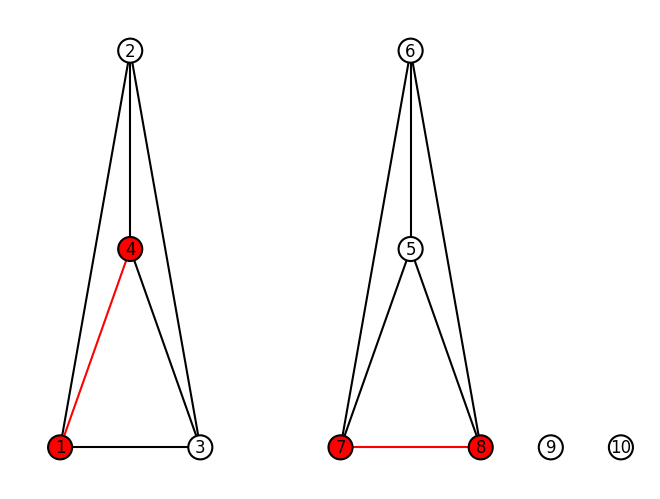

In [13]:
nontrivial_connected_components = [component for component in nx.connected_components(g) if len(component) > 1]

nodes_colors = ["white"] * g.number_of_nodes()
edges_colors = ["black"] * g.number_of_edges()

for component in nontrivial_connected_components:
    subgraph = g.subgraph(component)
    
    eccentricities = sorted(nx.eccentricity(subgraph).items(), key=lambda item: item[1], reverse=True)
    max_eccentricity_node = eccentricities[0][0]
    max_eccentricity = eccentricities[0][1]

    max_eccentricity_node_path = nx.single_source_shortest_path(subgraph, max_eccentricity_node)

    for node_path in max_eccentricity_node_path.values():
        if len(node_path) - 1 == max_eccentricity:
            diametr = node_path

    for node in diametr:
        node_for_coloring_index = list(g).index(node)
        nodes_colors[node_for_coloring_index] = 'red'

    for i in range(len(diametr) - 1):
            node1, node2 = diametr[i], diametr[i + 1]
            edge = (node1, node2) if (node1, node2) in list(g.edges) else (node2, node1)
            edge_index = list(g.edges).index(edge)
            edges_colors[edge_index] = "red"

nx.draw(g, pos, with_labels=True, node_color=nodes_colors, 
    edge_color=edges_colors, edgecolors='black', linewidths=1.5, width=1.5)
plt.show()

### 6 Depth spanning forest

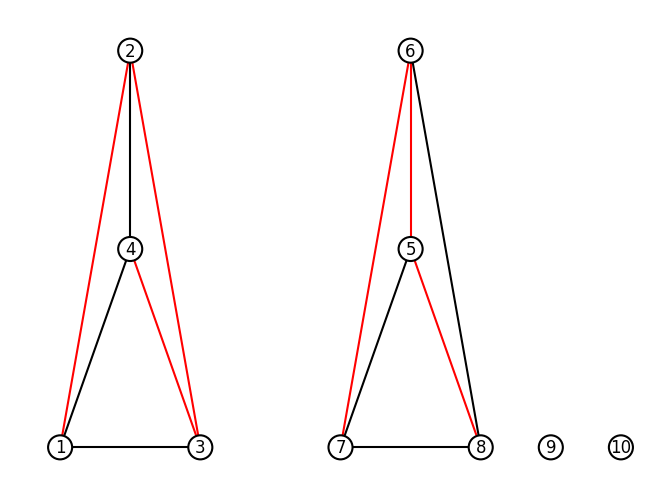

In [14]:
connected_components = nx.connected_components(g)
nodes_colors = ["white"] * g.number_of_nodes()
edges_colors = ["black"] * g.number_of_edges()

for component in connected_components:
    subgraph = g.subgraph(component)

    for edge in list(nx.dfs_edges(subgraph)):
        node1, node2 = edge[0], edge[1]
        edge = (node1, node2) if (node1, node2) in list(g.edges) else (node2, node1)
        edge_index = list(g.edges).index(edge)
        edges_colors[edge_index] = "red"

nx.draw(g, pos, with_labels=True, node_color=nodes_colors, 
    edge_color=edges_colors, edgecolors='black', linewidths=1.5, width=1.5)
plt.show()